In [1]:
import numpy as np  
import matplotlib.pyplot as plt

In [ ]:
def DiaelectricoCircular(n=1, Origen =[0,0], Radio = 1):
    EspacioIndices[(X - Origen[0])**2 + (Y - Origen[1])**2 <= Radio**2] = n
'''
def DiaelectricoRectangular(n=1,IntervaloX=[Espacio[0, 0], Espacio[0, -1]],IntervaloY=[Espacio[1, 0], Espacio[1, -1]]):
    mask = ((X >= IntervaloX[0]) & (X <= IntervaloX[1]) & (Y >= IntervaloY[0]) & (Y <= IntervaloY[1]))
    EspacioIndices[mask] = n
'''
#Es posible crear un diaelectrico rectangular pero el codigo no lo va a simular incorrectamente en estado actual, sera un trabajo para despues, solo me enfocare en circulos

def IndiceEspacio(x, y):
    j = np.argmin(np.abs(Espacio[0] - x))   # columna (x)
    i = np.argmin(np.abs(Espacio[1] - y))   # fila (y)
    return EspacioIndices[i, j]

def AnguloVec(Vec1,Vec2):
    return np.arccos((np.vdot(Vec1,Vec2))/(np.linalg.norm(Vec1)*np.linalg.norm(Vec2) ))

def AnguloRefractado(n1,n2,Oi):
    return np.arcsin(n1/n2 * np.sin(Oi))

def VectorCirculo(a,b,OrigenC):
    return np.array([a - OrigenC[0], b - OrigenC[1]])

def Rotar(vec, ang):
    #Utilizando la matriz de rotacion
    c, s = np.cos(ang), np.sin(ang)
    return np.array([c * vec[0] - s * vec[1], s * vec[0] + c * vec[1]])

def Refractar(VecI, VecN, n1, n2):
    a = -VecN                                             
    Anguloincidente = AnguloVec(VecI, a)                 
    AnguloTransmitido = AnguloRefractado(n1, n2, Anguloincidente)

    signo = np.sign(a[0]*VecI[1] - a[1]*VecI[0])           # lado de la inclinación

    if np.isnan(AnguloTransmitido):                        # reflexión total
        return Rotar(VecN, -signo * Anguloincidente)
    return Rotar(VecI, -signo * (Anguloincidente - AnguloTransmitido))

def IndiceExacto(px, py):
    for j in range(O.shape[0]):
        if (px - O[j, 0])**2 + (py - O[j, 1])**2 <= R[j]**2:
            return N[j], j
    return 1.0, None


'''
def Reflectar(VecI, VecN):
    a = -VecN
    Anguloincidente = AnguloVec(VecI, a)
    signo = np.sign(a[0]*VecI[1] - a[1]*VecI[0])
    return Rotar(VecN, -signo * Anguloincidente)
    
def AmplitudTransmision(a, b, E):
    return (2)/(a+b) * E

def AmplitudRefleccion(a, b, E):
    return (a-b)/(a+b) *E
'''



'\ndef Reflectar(VecI, VecN):\n    a = -VecN\n    Anguloincidente = AnguloVec(VecI, a)\n    signo = np.sign(a[0]*VecI[1] - a[1]*VecI[0])\n    return Rotar(VecN, -signo * Anguloincidente)\n    \ndef AmplitudTransmision(a, b, E):\n    return (2)/(a+b) * E\n\ndef AmplitudRefleccion(a, b, E):\n    return (a-b)/(a+b) *E\n'

In [ ]:
Espacio =np.array([np.linspace(-20, 20,1000),np.linspace(-20, 20, 1000)])
X , Y = np.meshgrid(Espacio[0], Espacio[1])
EspacioIndices = np.ones_like(X, dtype=float)

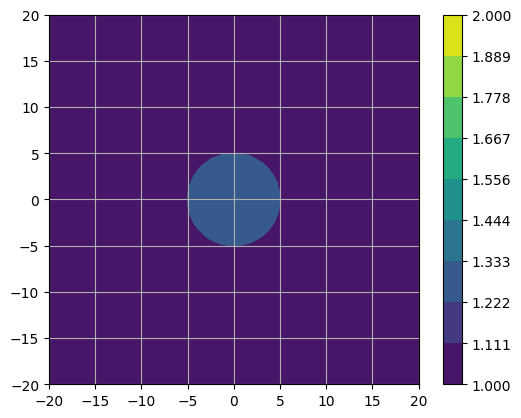

In [4]:
O1 = [0,0]
R1 = 5
IndiceCirculo = 1.3
DiaelectricoCircular(IndiceCirculo, O1, R1)
# Dibujar
plt.contourf(X, Y, EspacioIndices, levels= np.linspace(1,2,10))
plt.axis('scaled')
plt.colorbar()
plt.grid(True)
plt.show()

26.485748305045398
19.591979593718325


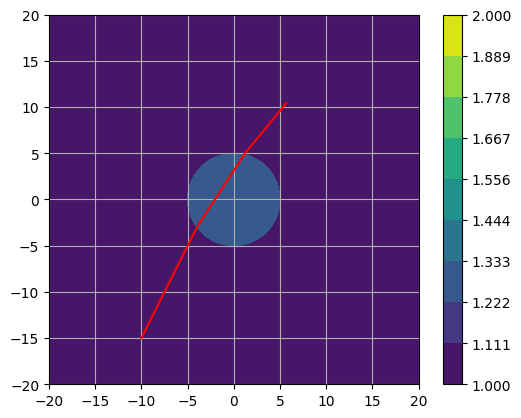

In [5]:
Vec1 = np.array([1.0, 2.0])
Vec1 = Vec1 / np.linalg.norm(Vec1)            
Origen = np.array([-10.0, -15.0])

t = np.linspace(0, 30, 4000)                     
x1 = np.full(t.size, np.nan)                    
y1 = np.full(t.size, np.nan)
x1[0], y1[0] = Origen                           
dt = t[1] - t[0]

#Tranmision
for i in range(1, t.size):
    x1[i] = x1[i-1] + Vec1[0] * dt
    y1[i] = y1[i-1] + Vec1[1] * dt
    n1 = IndiceEspacio(x1[i-1], y1[i-1])
    n2 = IndiceEspacio(x1[i], y1[i])
    if n1 != n2:                        
        Vec2 = np.array(VectorCirculo(x1[i], y1[i], O1))   
        Vec2 = Vec2 / np.linalg.norm(Vec2)

        if np.dot(Vec2, Vec1) > 0:
            Vec2 = -Vec2
        Vec1 = Refractar(Vec1, Vec2, n1, n2)


    
print(np.degrees(AnguloVec(Vec1,-Vec2)))
print(np.degrees(AnguloRefractado(1, 1.33,AnguloVec(Vec1,-Vec2))))
plt.contourf(X, Y, EspacioIndices, levels= np.linspace(1,2,10))
plt.plot(x1, y1, color='r')
plt.axis('scaled')
plt.colorbar()
plt.grid(True)
plt.show()

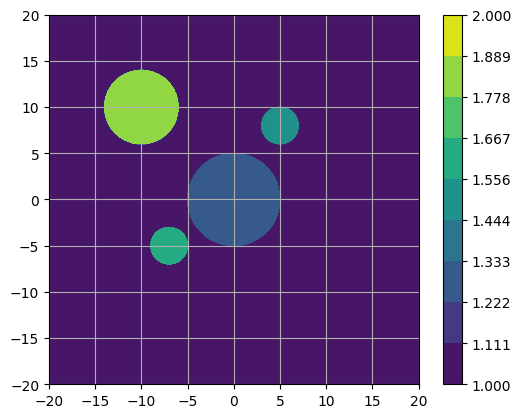

In [14]:
Espacio =np.array([np.linspace(-20, 20,1000),np.linspace(-20, 20, 1000)])
X , Y = np.meshgrid(Espacio[0], Espacio[1])
EspacioIndices = np.ones_like(X, dtype=float)

O = np.array(([0,0],[5,8],[-7,-5],[-10,10])) 
R = np.array(([5,2,2,4]))
N = np.array([1.33, 1.5, 1.6, 1.8])
DiaelectricoCircular(N[0], O[0], R[0])
DiaelectricoCircular(N[1], O[1], R[1])
DiaelectricoCircular(N[2], O[2], R[2])
DiaelectricoCircular(N[3], O[3], R[3])
# Dibujar
plt.contourf(X, Y, EspacioIndices, levels= np.linspace(1,2,10))
plt.axis('scaled')
plt.colorbar()
plt.grid(True)
plt.show()

In [11]:
def Transmision(Origen, Direccion, t):
    Vec1 = np.array(Direccion, dtype=float)
    Vec1 = Vec1 / np.linalg.norm(Vec1)

    x1 = np.full(t.size, np.nan)
    y1 = np.full(t.size, np.nan)
    x1[0], y1[0] = Origen
    dt = t[1] - t[0]

    for i in range(1, t.size):
        x1[i] = x1[i-1] + Vec1[0] * dt
        y1[i] = y1[i-1] + Vec1[1] * dt

        n1, j1 = IndiceExacto(x1[i-1], y1[i-1])
        n2, j2 = IndiceExacto(x1[i],   y1[i])

        if j1 != j2:                                  # cambió de medio
            j = j2 if j2 is not None else j1          # entra: j2, sale: j1
            Vec2 = VectorCirculo(x1[i], y1[i], O[j])
            Vec2 = Vec2 / np.linalg.norm(Vec2)
            if np.dot(Vec2, Vec1) > 0:                # la normal debe oponerse al rayo
                Vec2 = -Vec2

            Vec1 = Refractar(Vec1, Vec2, n1, n2)

            if np.dot(Vec1, Vec2) > 0:                # reflexión total
                x1[i], y1[i] = x1[i-1], y1[i-1]       # el punto vuelve al medio original

    return x1, y1

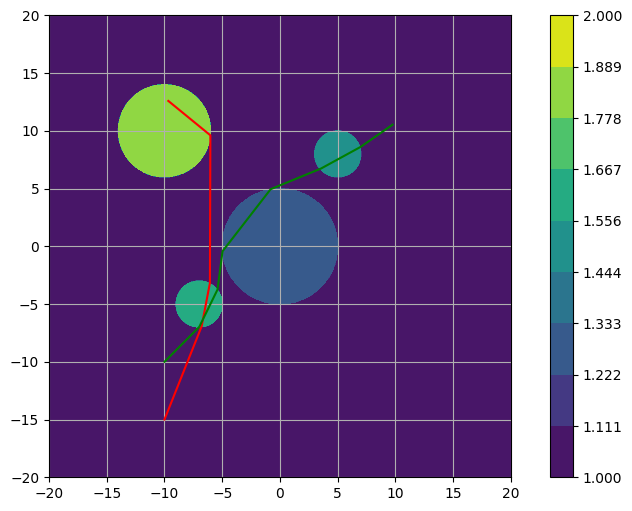

In [15]:
Vec1 = np.array([1.0, 2.5])           
Origen1 = np.array([-10.0, -15.0])
t = np.linspace(0, 30, 4000)                     

Vec2 = np.array([1.0, 1.0])           
Origen2 = np.array([-10.0, -10.0])
t = np.linspace(0, 30, 4000)  


x1, y1 = Transmision(Origen1, Vec1, t)
x2, y2 = Transmision(Origen2, Vec2, t)


plt.figure(figsize=(10,6))
plt.contourf(X, Y, EspacioIndices, levels= np.linspace(1,2,10))
plt.plot(x1, y1, color='r')
plt.plot(x2, y2, color = 'g')
plt.axis('scaled')
plt.colorbar()
plt.grid(True)
plt.show()